In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import urllib.request
urllib.request.urlretrieve('https://github.com/zbz95/Intro_to_ML/raw/main/insurance.csv', 'insurance.csv')

('insurance.csv', <http.client.HTTPMessage at 0x74a6f5659ba0>)

# Упражнение 1
Откройте файл insurance.csv

Поделите файл на три блока train, validation, test. Размер train-80% всех данных, validation 10% всех данных, test 10% всех данных

Стандартизируйте features во всех трех блоках используя StandardScaler

In [2]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,expenses
0,19,0,27.9,0,1,16884.92
1,18,1,33.8,1,0,1725.55
2,28,1,33.0,3,0,4449.46
3,33,1,22.7,0,0,21984.47
4,32,1,28.9,0,0,3866.86


In [17]:
df.describe()

,age,sex,bmi,children,smoker,expenses
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,0.505232,30.665471,1.094918,0.204783,13270.422414
std,14.049960,0.500160,6.098382,1.205493,0.403694,12110.011240
min,18.000000,0.000000,16.000000,0.000000,0.000000,1121.870000
25%,27.000000,0.000000,26.300000,0.000000,0.000000,4740.287500
50%,39.000000,1.000000,30.400000,1.000000,0.000000,9382.030000
75%,51.000000,1.000000,34.700000,2.000000,0.000000,16639.915000
max,64.000000,1.000000,53.100000,5.000000,1.000000,63770.430000


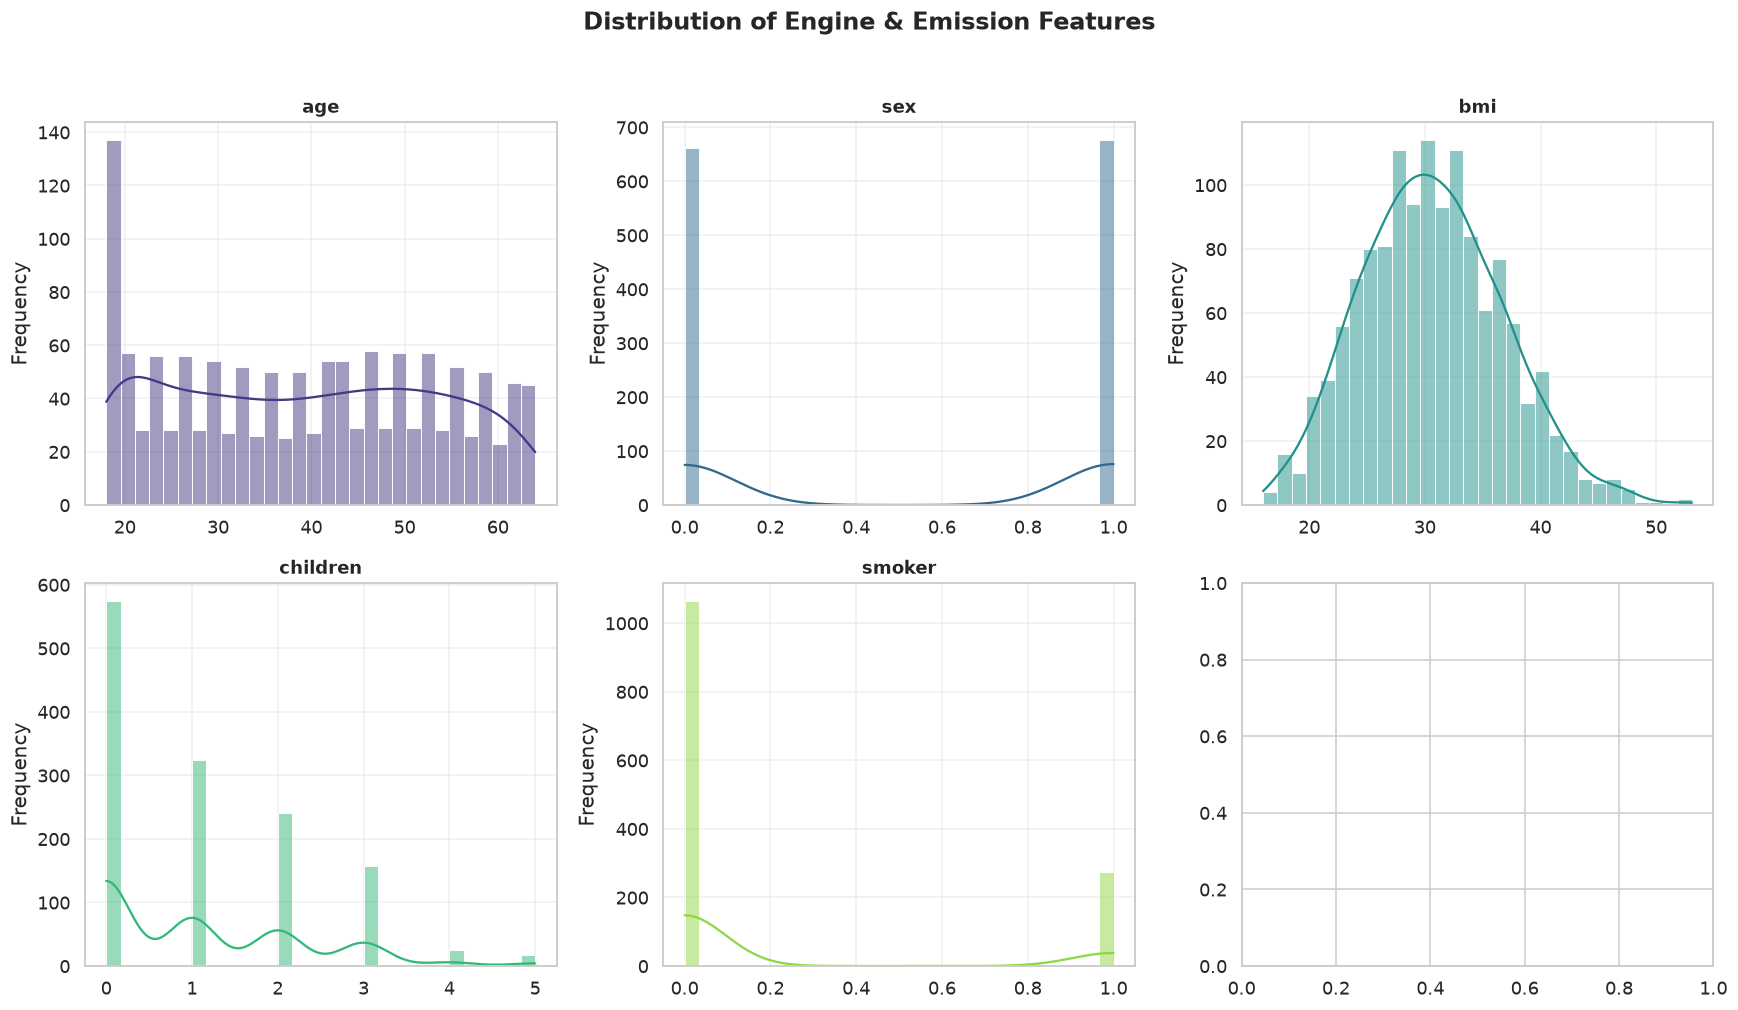

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['age','sex','bmi','children','smoker']
viz = df[cols].copy()
cdf =  df[cols].copy()

sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

# --- 3) ساخت شبکه‌ی 2×3 هیستوگرام با KDE ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colors = sns.color_palette("viridis", len(cols))

for i, col in enumerate(cols):
    sns.histplot(
        data=viz,
        x=col,
        bins=30,
        kde=True,
        color=colors[i],
        edgecolor='white',
        linewidth=0.6,
        ax=axes[i]
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')      # محور x رو خالی می‌کنیم چون عنوان بالا هست
    axes[i].set_ylabel('Frequency')
    axes[i].grid(alpha=0.3)

# --- 4) تنظیم فاصله‌ها و یک عنوان کلی ---
fig.suptitle('Distribution of Engine & Emission Features',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error


# ---------- helper: plot fitted line/curve ---------- 
def _plot_fit(model, df, feature_col, target_col, title): # create plot 
    x_all = df[feature_col].values
    y_all = df[target_col].values
    
    x_smooth = np.linspace(x_all.min(), x_all.max(), 100).reshape(-1, 1)
    x_smooth_df = pd.DataFrame(x_smooth, columns=[feature_col])

    plt.scatter(x_all, y_all)
    plt.plot(x_smooth, model.predict(x_smooth_df), color="red")
    plt.xlabel(feature_col)
    plt.ylabel(target_col)
    plt.title(title)
    plt.show()


# ---------- 1) Linear Regression on a dataframe ----------
def linear_regression_analysis(df, feature_col, target_col, plot=True):
    X = df[[feature_col]]
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    print(f"[Linear]      R² = {r2:.4f} | MSE = {mse:.4f}")

    if plot:
        _plot_fit(model, df, feature_col, target_col,
                  f"Linear Regression  (R²={r2:.4f})")

    # return model, y_test, y_pred, r2, mse


# ---------- 2) Polynomial Regression (degree=2) on a dataframe ----------
def polynomial_regression_analysis(df, feature_col, target_col, degree=2, plot=True):
    X = df[[feature_col]]
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("lin",  LinearRegression()),
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    if plot:
        _plot_fit(model, df, feature_col, target_col,
                  f"Polynomial Regression (deg={degree})  (R²={r2:.4f})")
    else :
        print(f"[Polynomial d={degree}]  R² = {r2:.4f} | MSE = {mse:.4f}")

    # return model, y_test, y_pred, r2, mse

In [6]:
# why he like that 

train , validation = train_test_split(
    df,
    test_size=0.2,
    shuffle=True
)

validation, test = train_test_split(
    validation,
    test_size=0.5,
    shuffle=True
)


"Train 80% Validation 10%  Test 10%"

'Train 80% Validation 10%  Test 10%'

In [ ]:
for col in ['age','sex','bmi','children','smoker'] : 
    linear_regression_analysis(df, f"{col}", "expenses")

[Linear]      R² = 0.0017 | MSE = 154985514.6514


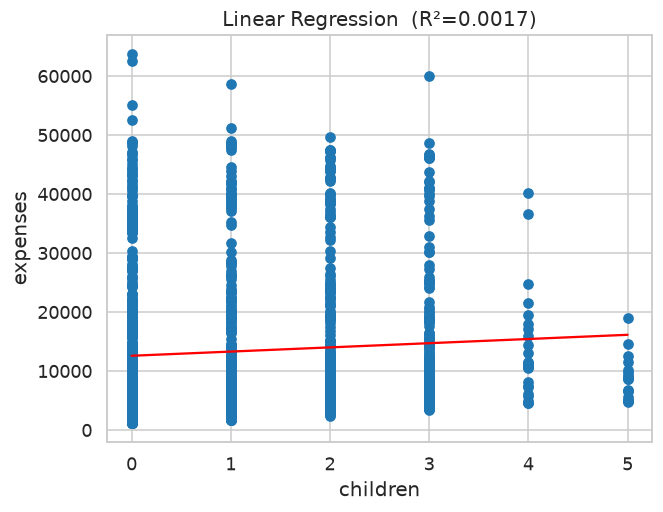

In [7]:
linear_regression_analysis(df, "children", "expenses")


[Linear]      R² = 0.0026 | MSE = 154843204.3422


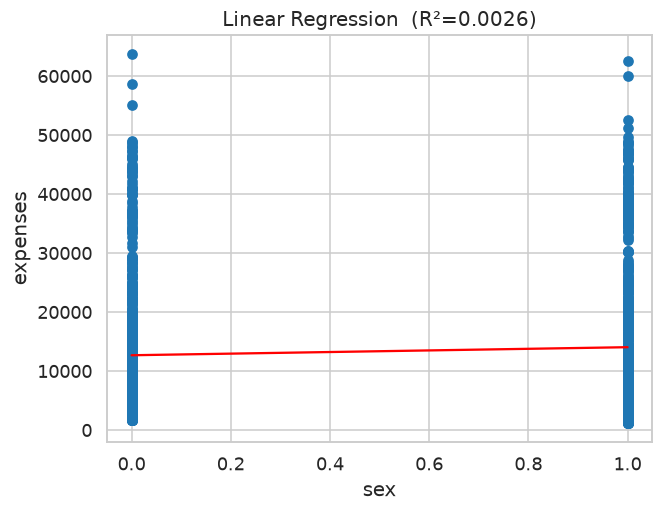

In [8]:
linear_regression_analysis(df, "sex", "expenses")


[Linear]      R² = 0.6602 | MSE = 52745963.7567


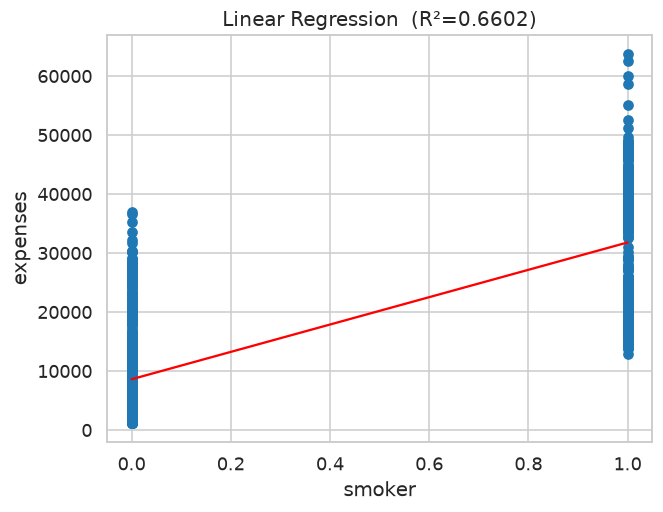

In [9]:
linear_regression_analysis(df, "smoker", "expenses")


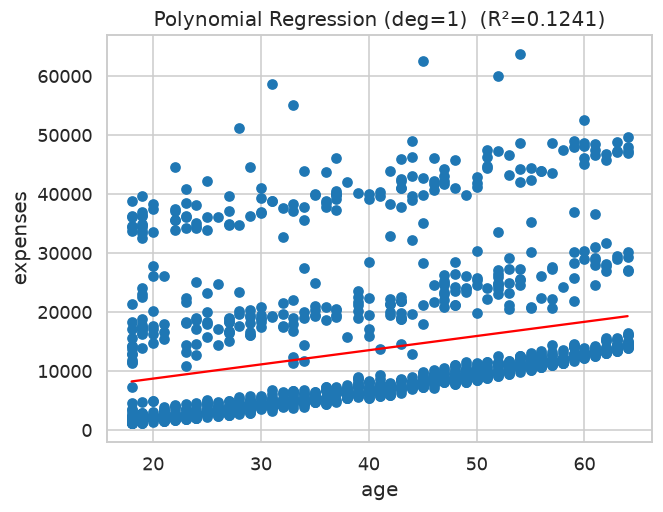

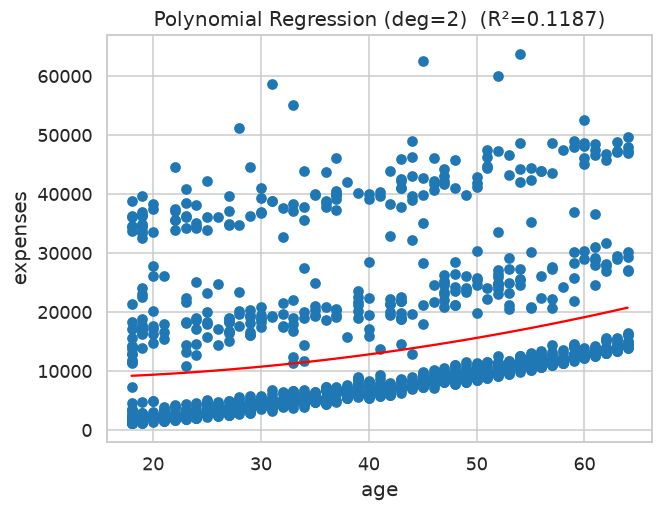

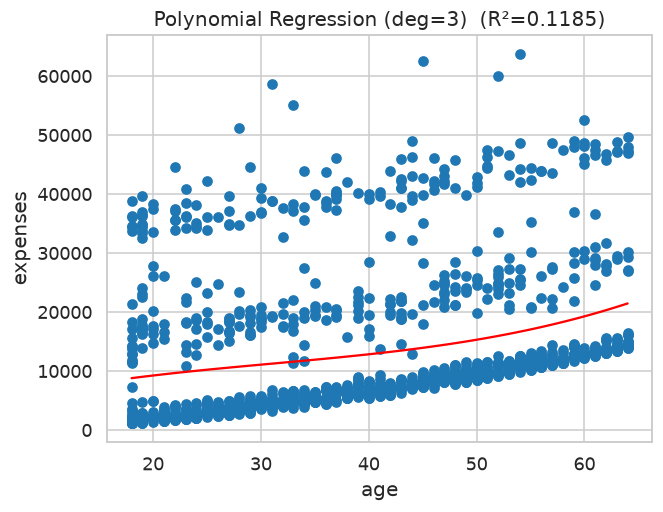

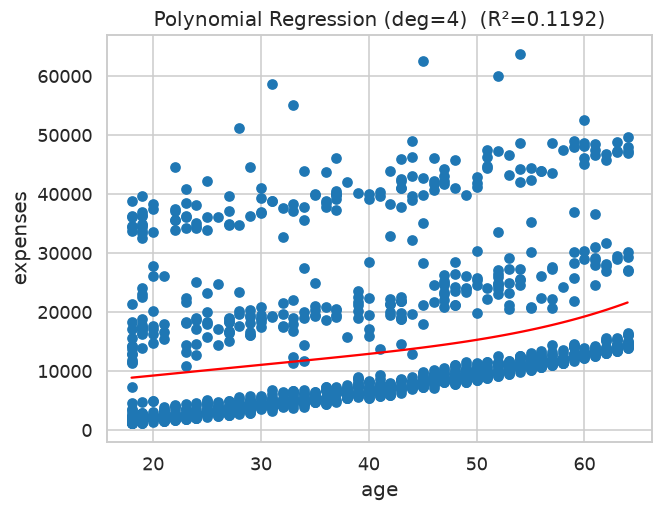

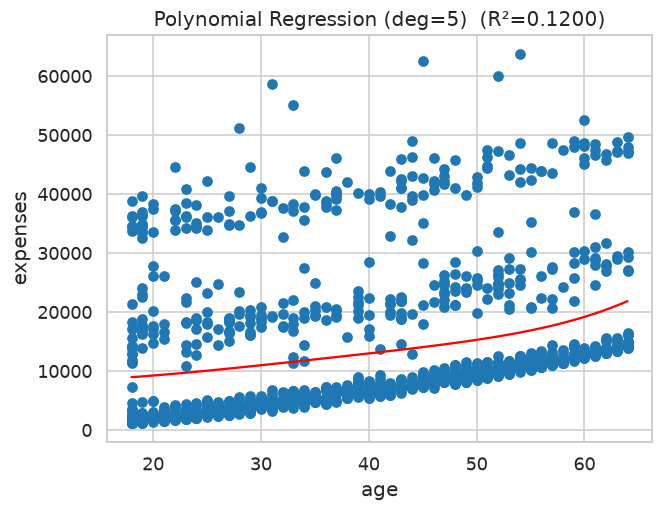

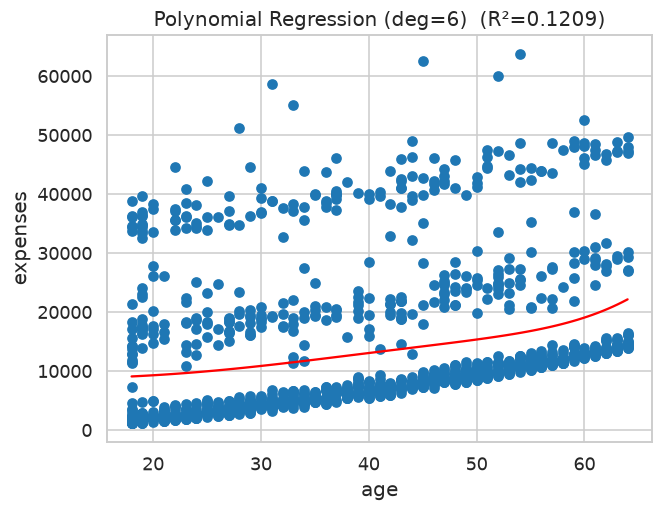

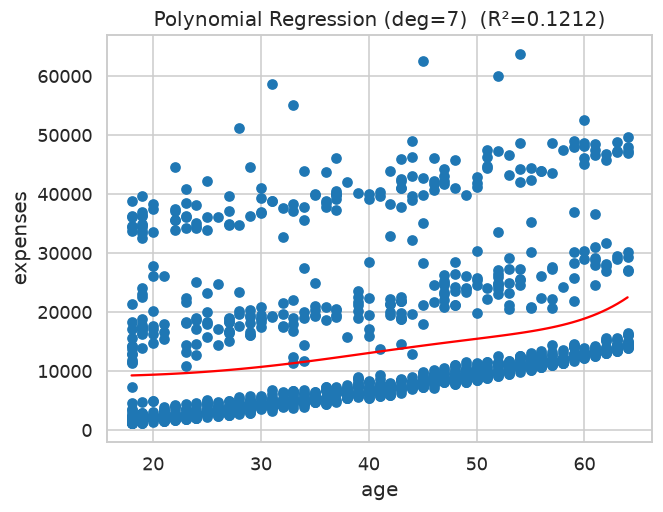

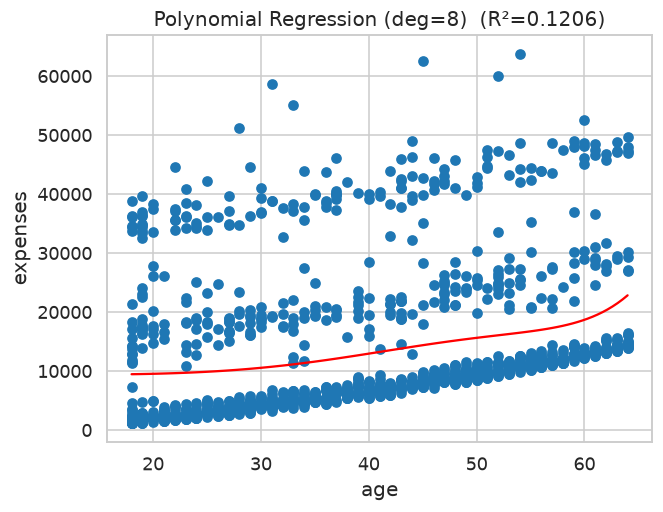

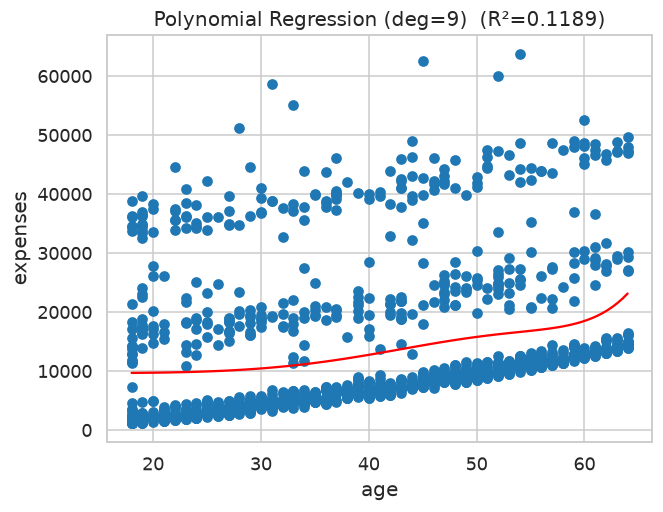

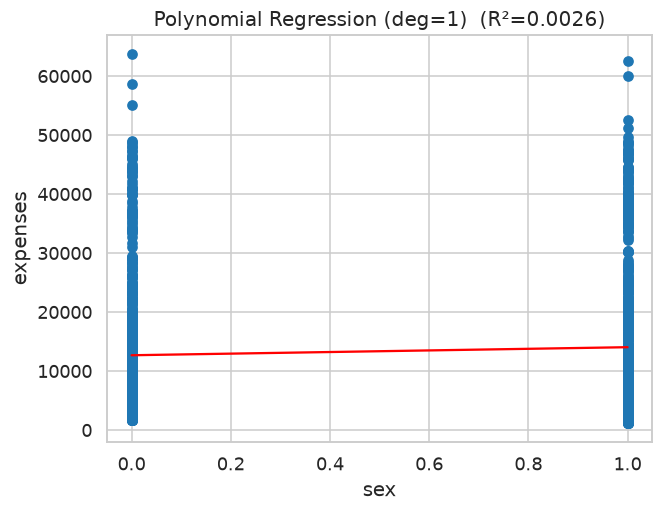

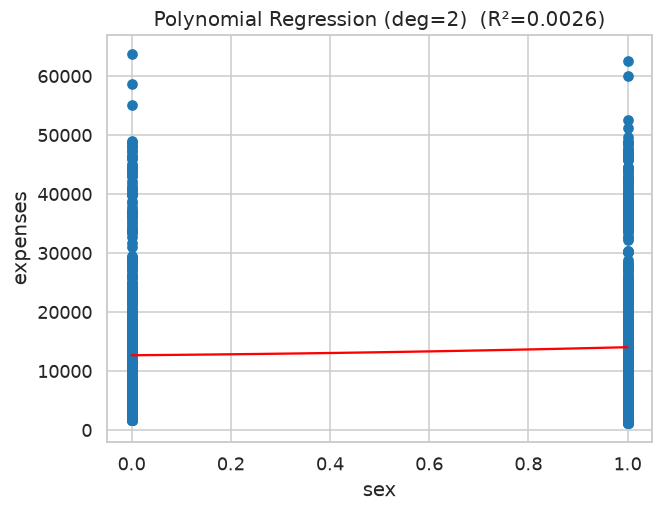

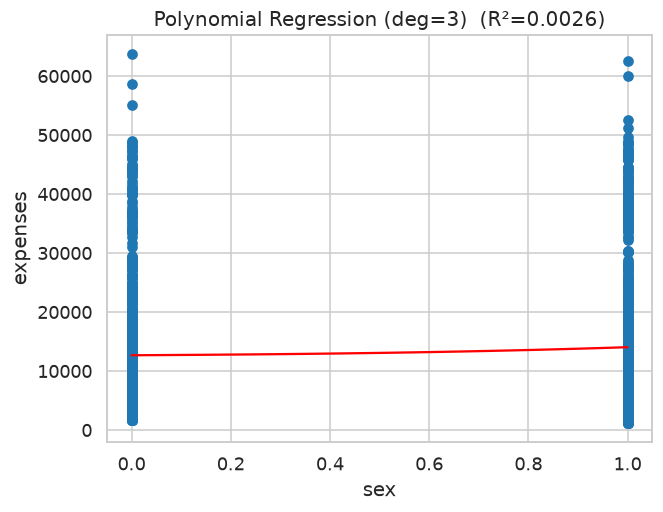

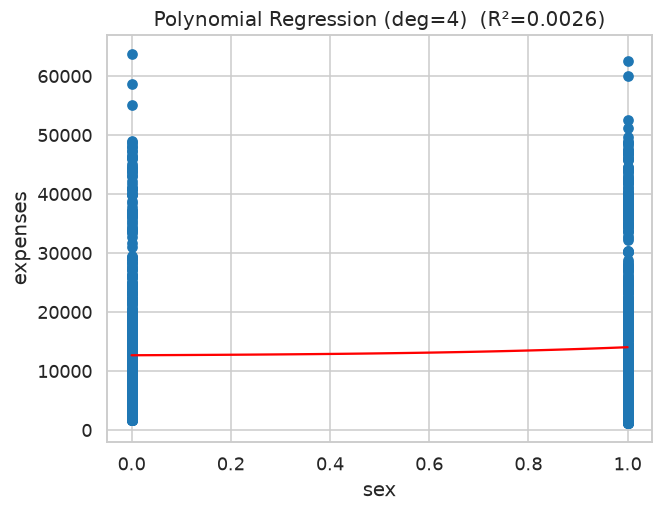

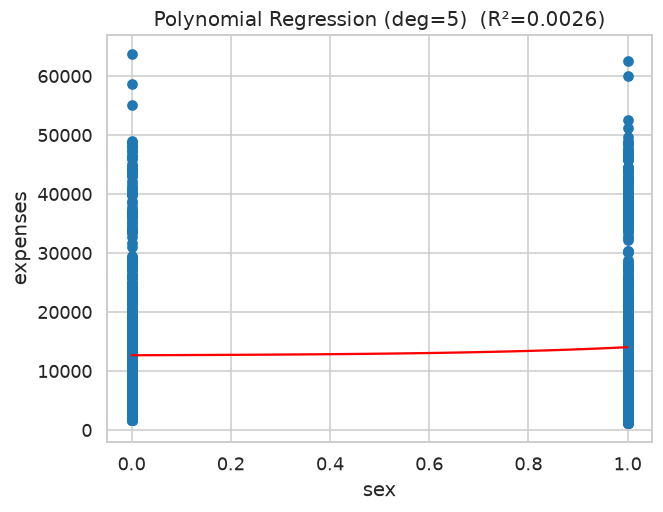

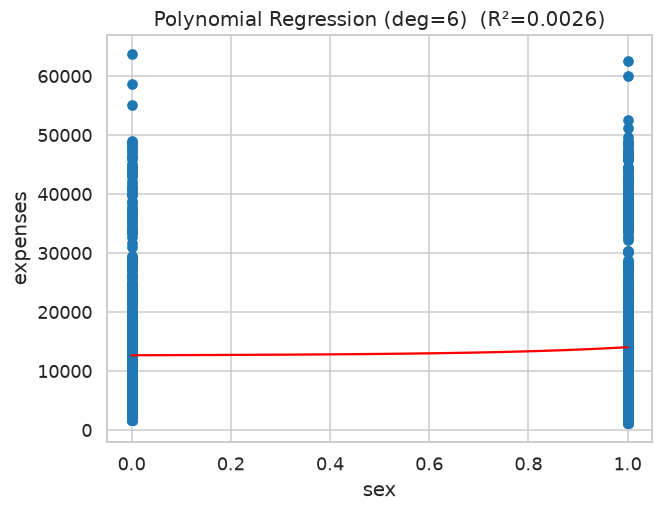

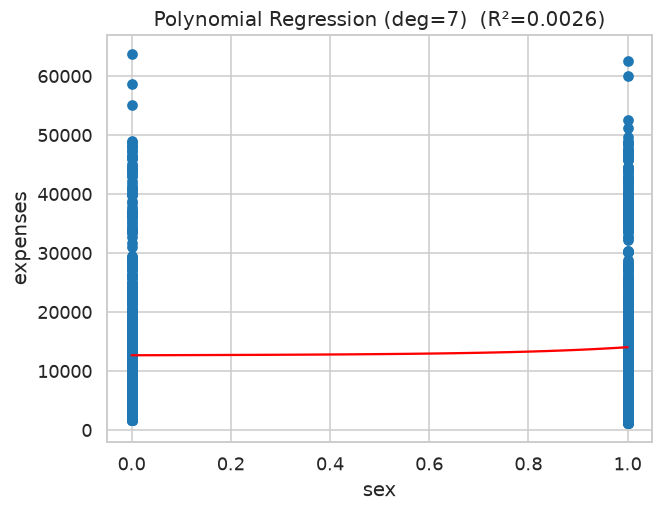

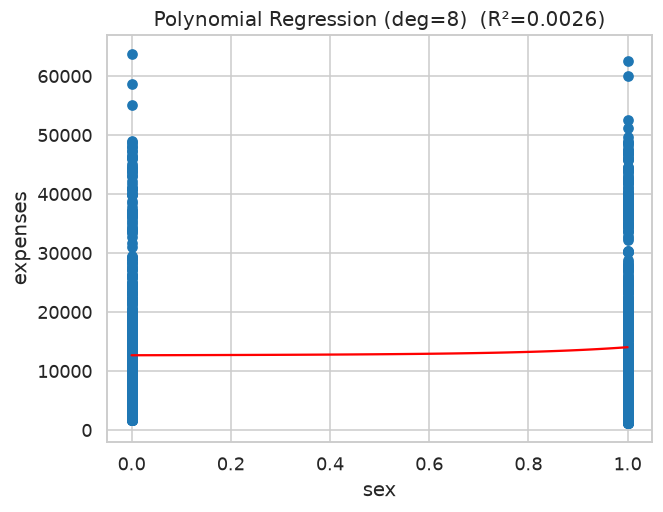

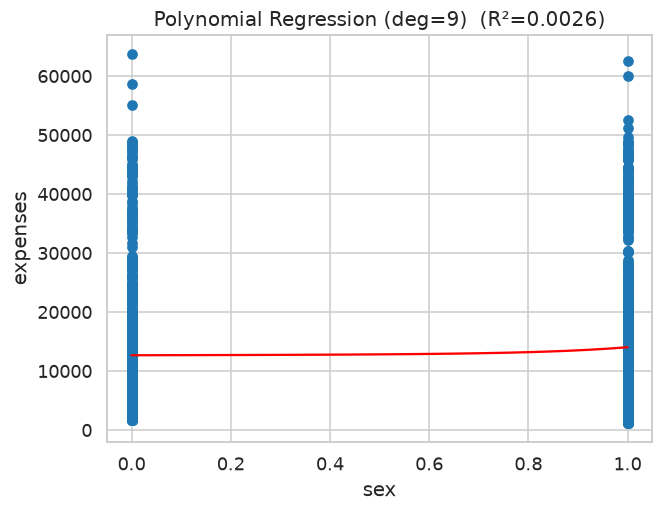

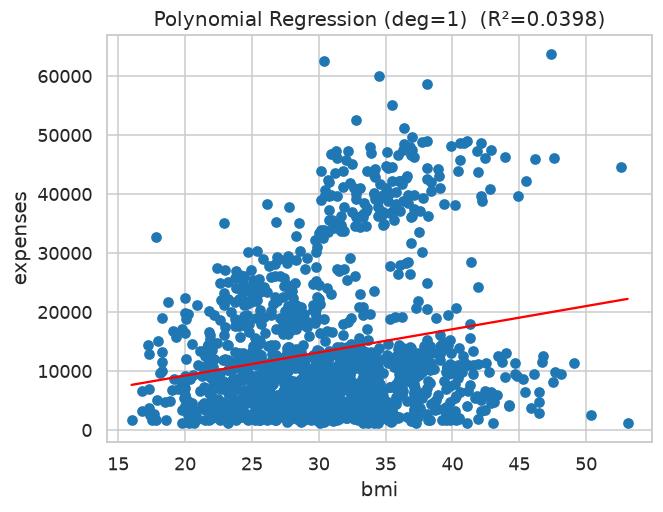

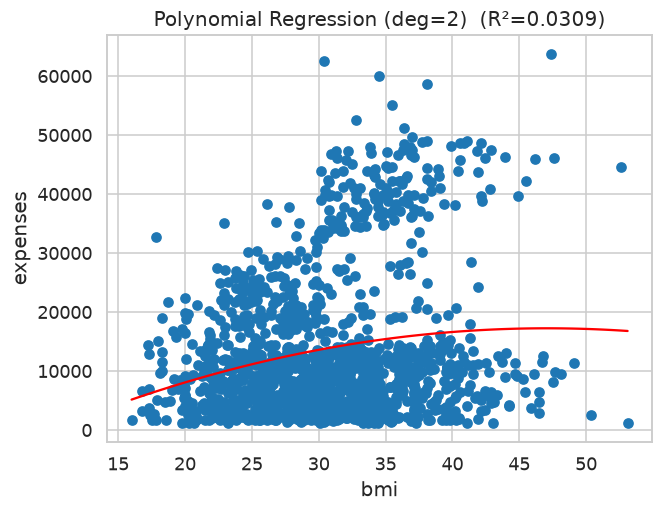

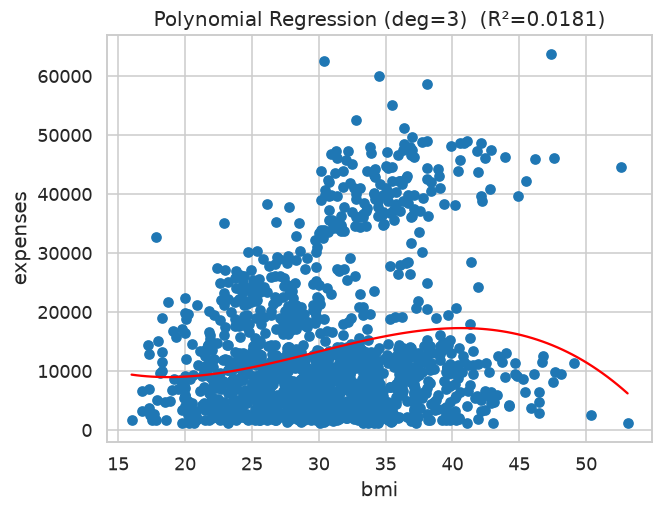

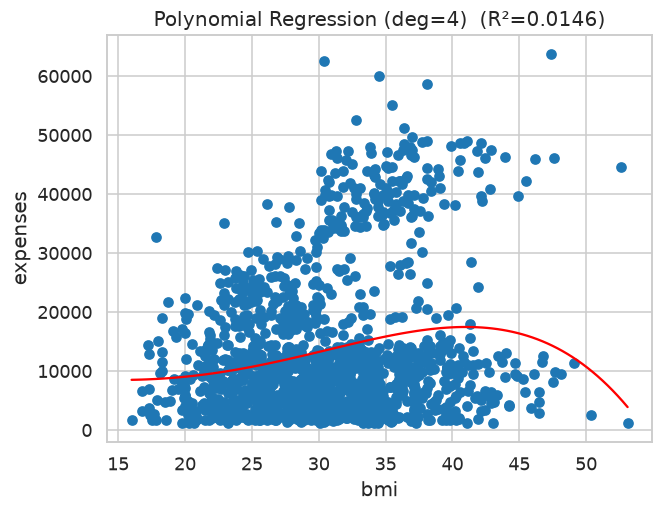

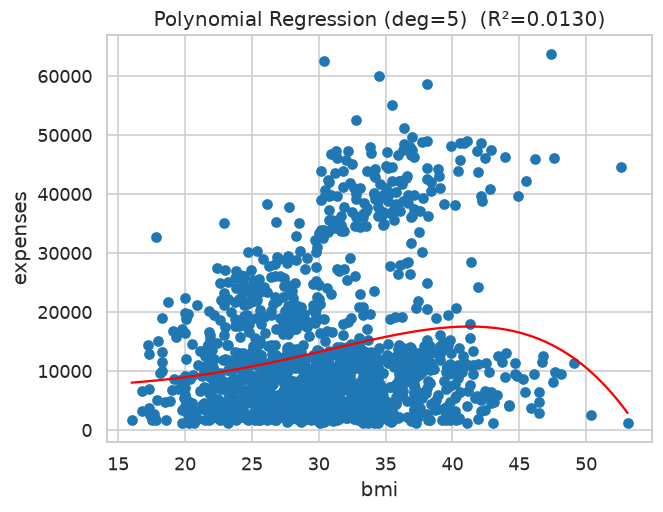

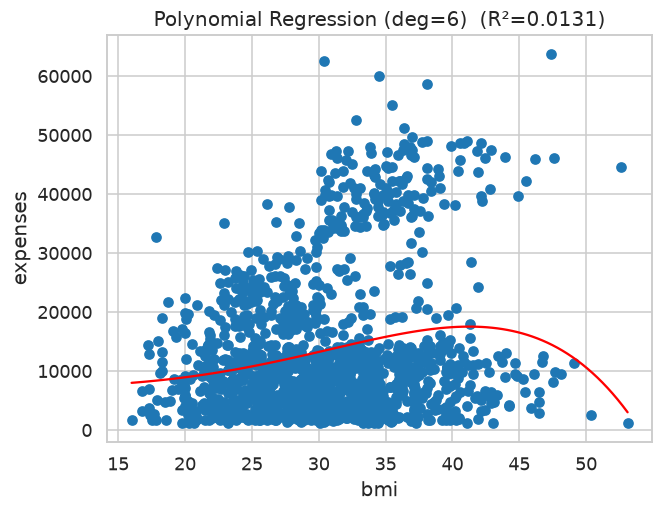

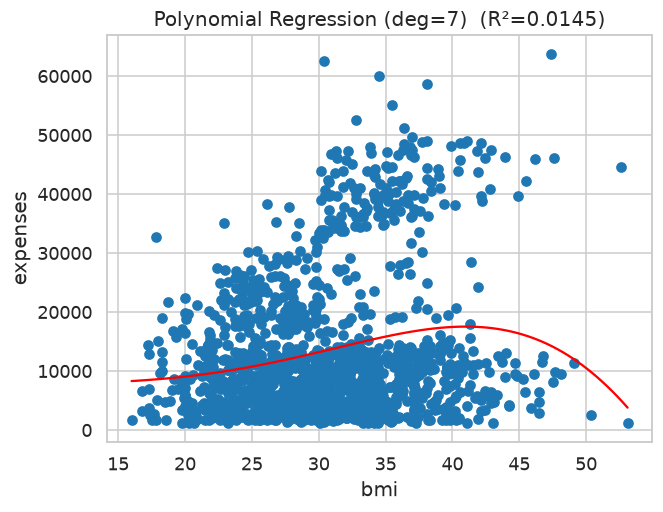

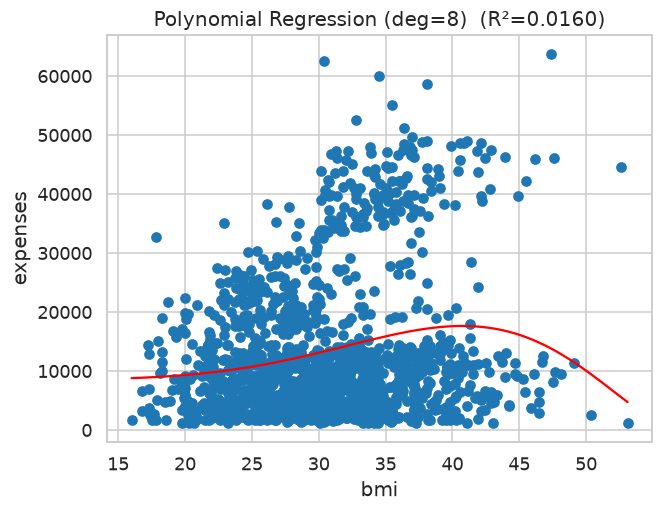

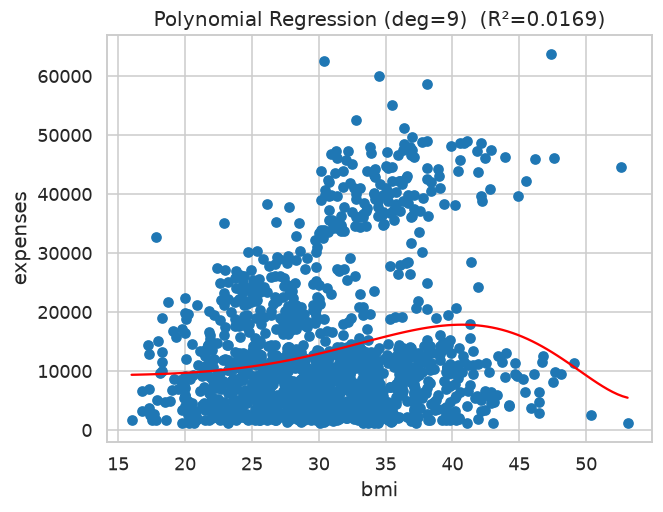

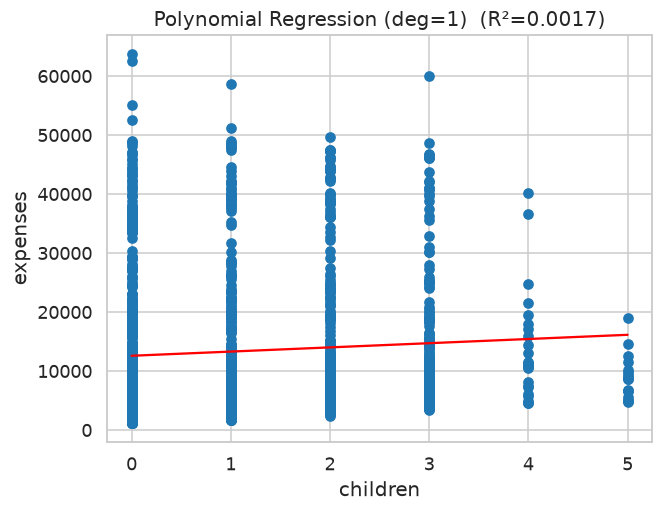

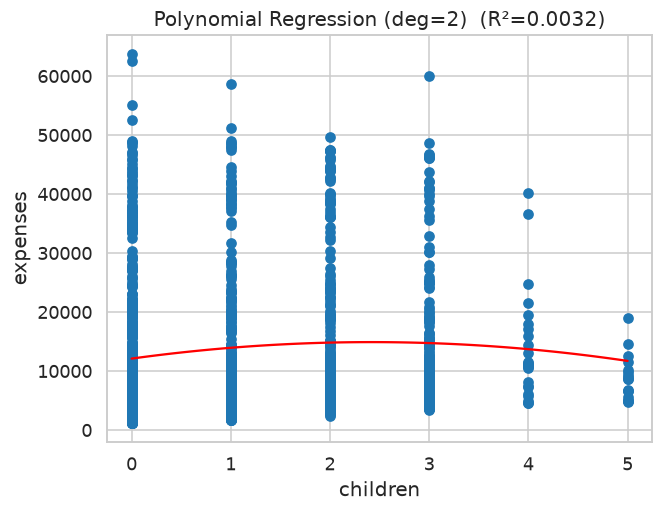

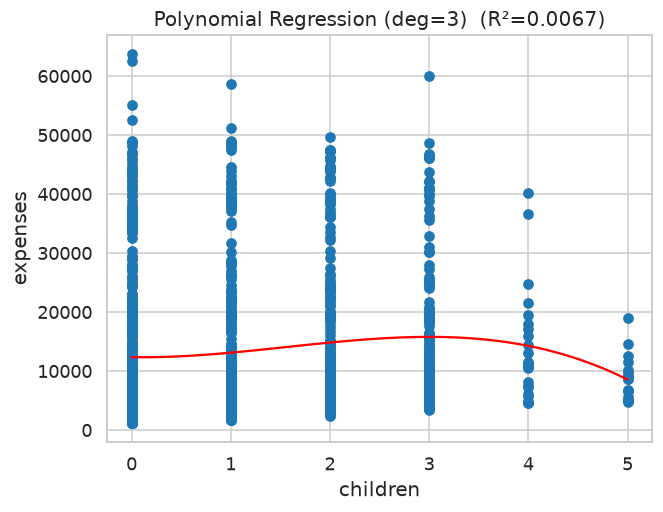

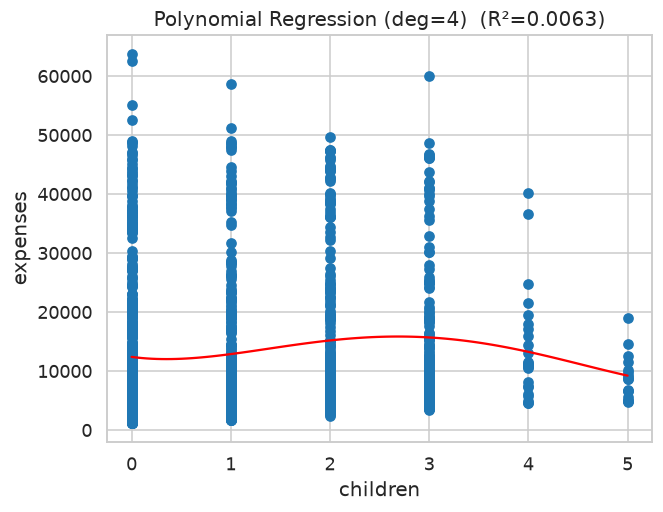

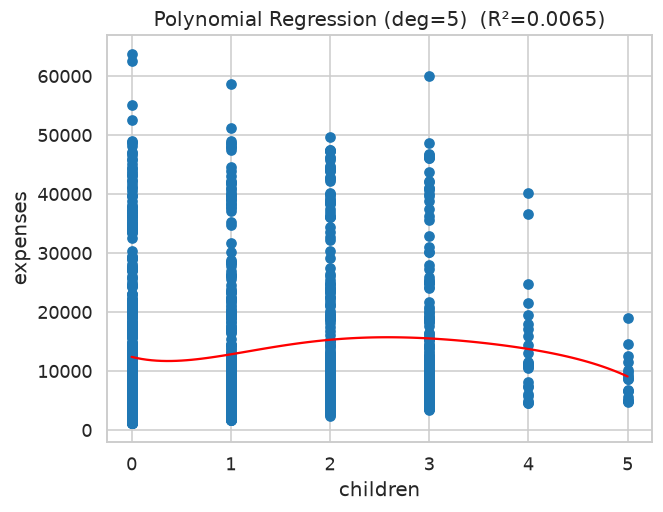

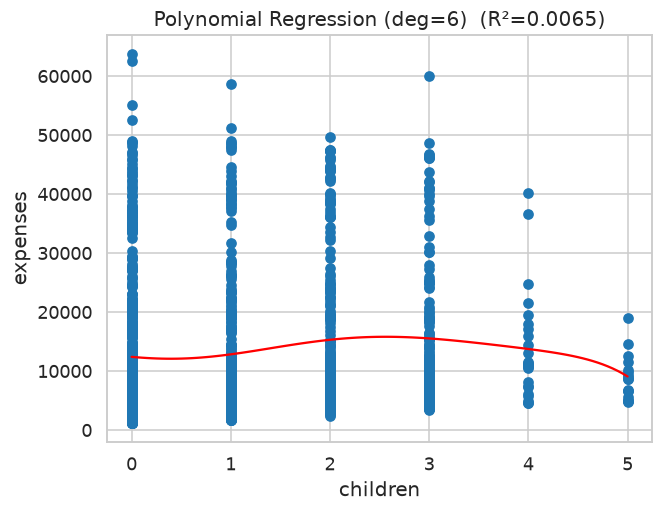

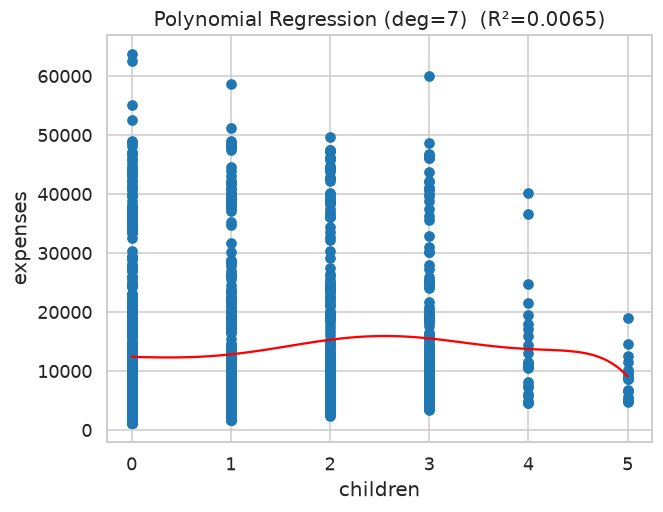

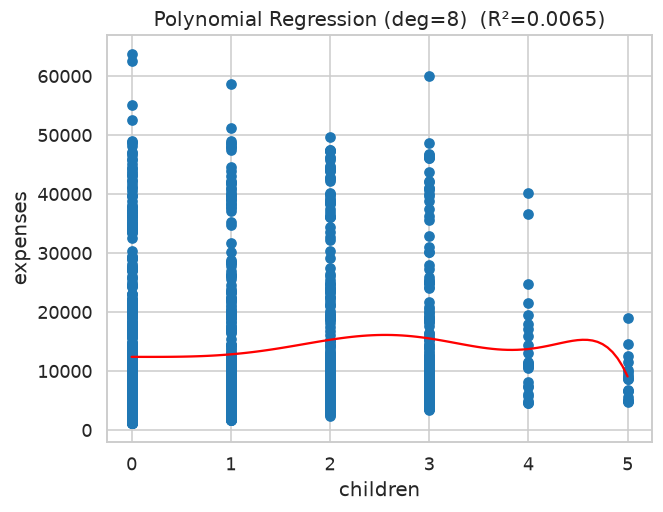

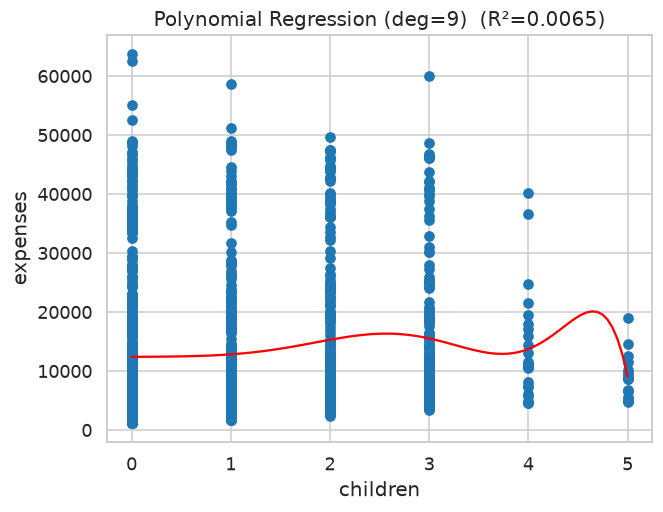

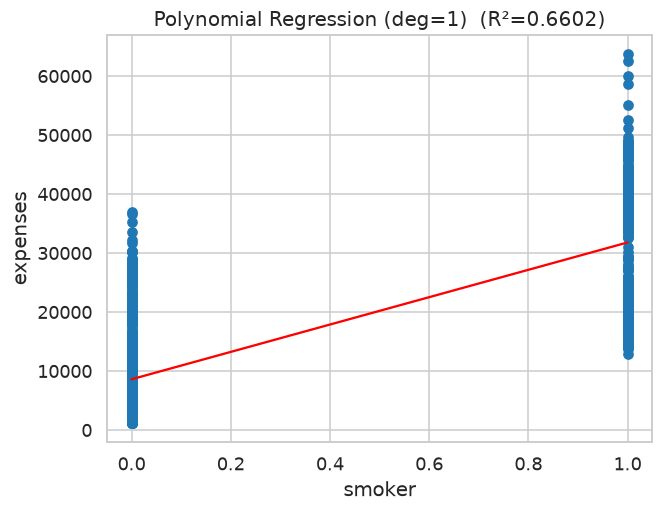

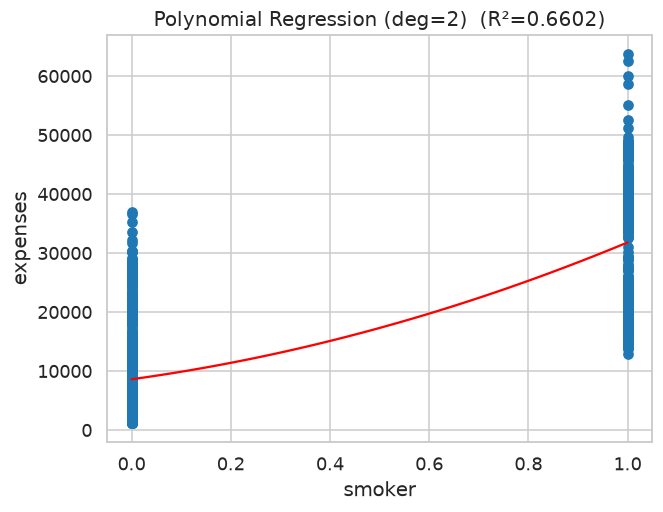

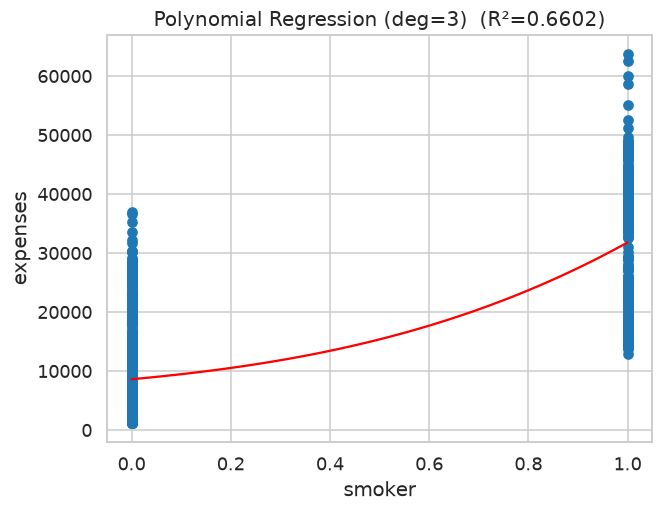

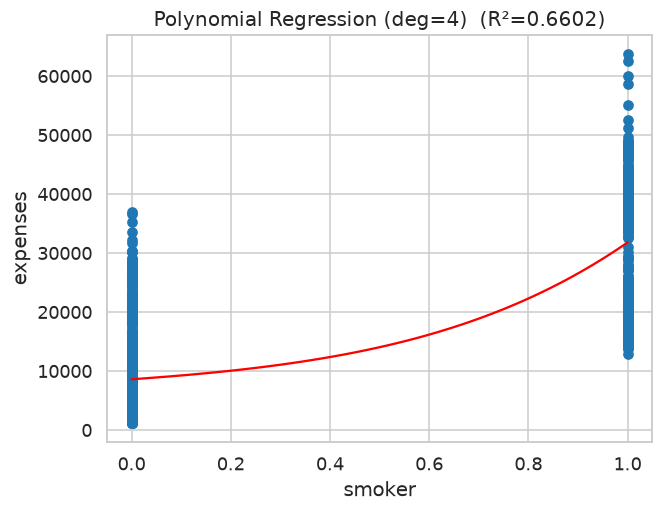

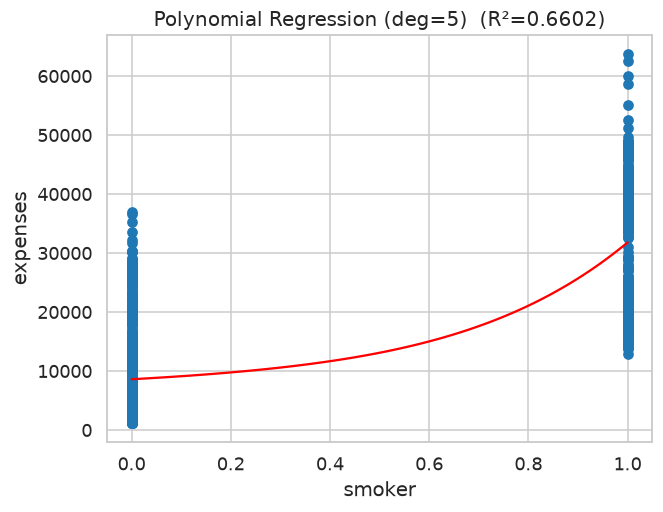

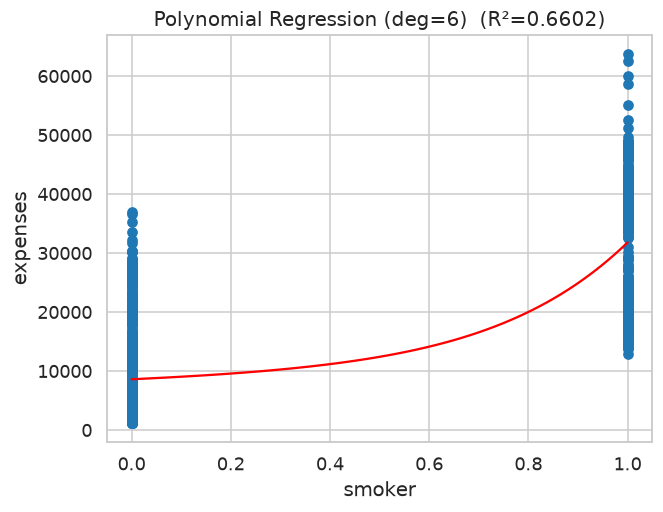

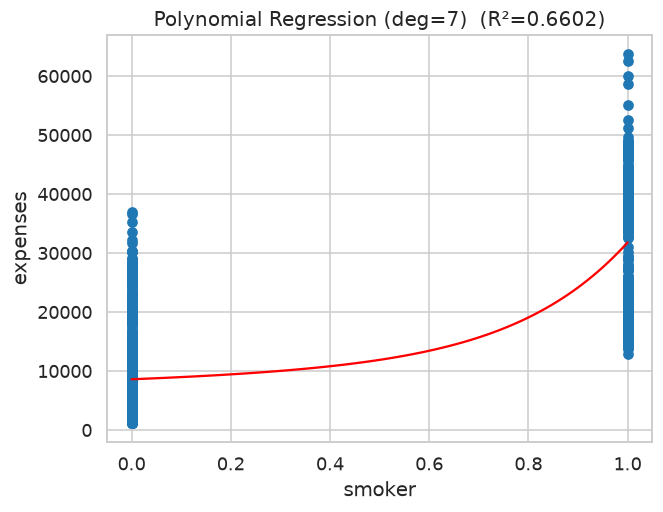

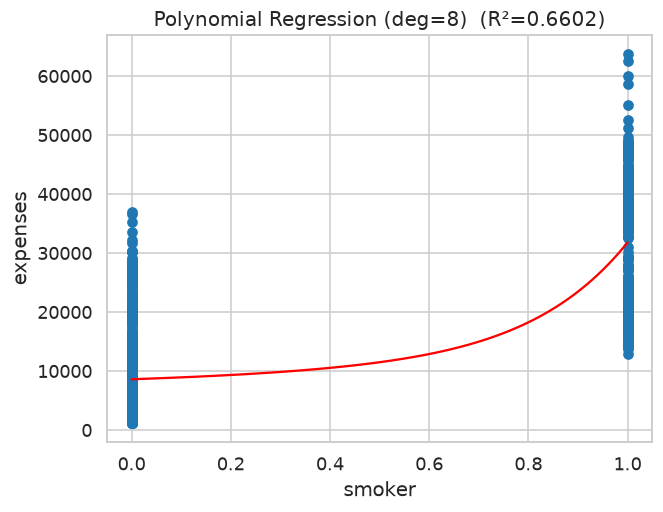

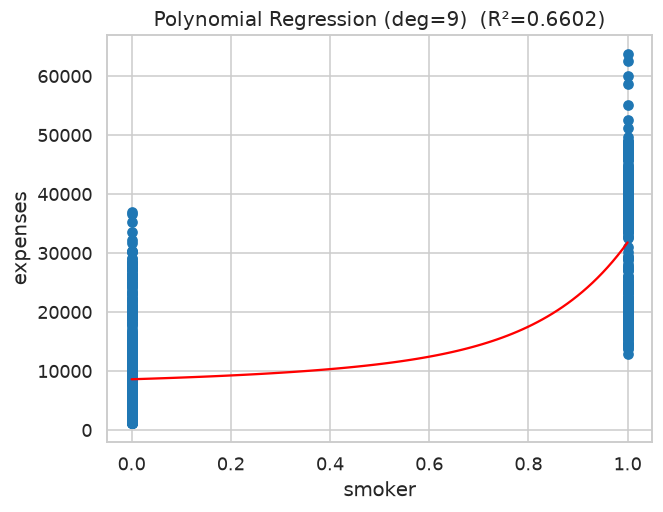

In [37]:
for col in ['age','sex','bmi','children','smoker'] : 
    for i in range(1,10):
        polynomial_regression_analysis(df, f"{col}", "expenses",degree=i)



# age oke 
# sex zeyad tasir nadare 
# bmi regrasson ro bekesh 

In [18]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
 # here we have to feather progrming 

# Input features
features = ['age', 'sex', 'bmi', 'children', 'smoker']

# Separate X and y
X_train = train[features]
y_train = train['expenses']

X_val = validation[features]
y_val = validation['expenses']

X_test = test[features]
y_test = test['expenses']


# Feature types
numeric_features = ['age', 'bmi', 'children']
categorical_features = ['smoker']


# Numeric pipeline
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    PolynomialFeatures(degree=2, include_bias=False),
    # StandardScaler()
)


# Categorical pipeline
categorical_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)


# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline, numeric_features),
        ('categorical', categorical_pipeline, categorical_features)
    ]
)


# Model
model = make_pipeline(
    preprocessor,
    LinearRegression()
)


# Train
model.fit(X_train, y_train)


# Validation prediction
val_pred = model.predict(X_val)

print("Validation R²:", r2_score(y_val, val_pred))
print("Validation RMSE:", mean_squared_error(y_val, val_pred) ** 0.5)
# Final test evaluation
test_pred = model.predict(X_test)

print("Test R²:", r2_score(y_test, test_pred))
print("Test RMSE:", mean_squared_error(y_test, test_pred) ** 0.5)

Validation R²: 0.7431096259797059
Validation RMSE: 5672.7086902192905
Test R²: 0.7585053965464239
Test RMSE: 5958.737289336623


In [44]:

from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Numeric pipeline
numeric_pipeline = ColumnTransformer(
    transformers=[
        ('age', PolynomialFeatures(degree=1, include_bias=False), ['age']),
        ('bmi', PolynomialFeatures(degree=1, include_bias=False), ['bmi']),
        ('children', PolynomialFeatures(degree=4, include_bias=False), ['children'])
    ],
    remainder='drop'
)

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', make_pipeline(
            numeric_pipeline,
            StandardScaler()
        ), ['age', 'bmi', 'children']),

        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         [ 'smoker'])
    ]
)

# Model
model = make_pipeline(
    preprocessor,
    LinearRegression()
)

# Train
model.fit(X_train, y_train)

# Validation
val_pred = model.predict(X_val)

print("Validation R²:", r2_score(y_val, val_pred))
print("Validation RMSE:", mean_squared_error(y_val, val_pred) ** 0.5)

# Final Test
test_pred = model.predict(X_test)

print("Test R²:", r2_score(y_test, test_pred))
print("Test RMSE:", mean_squared_error(y_test, test_pred) ** 0.5)


Validation R²: 0.7449234251921086
Validation RMSE: 6714.535728449929
Test R²: 0.7468598645406035
Test RMSE: 4907.081726489882


In [6]:
scaler = StandardScaler() # not now 
scaler.fit(train[['age','sex','bmi','children','smoker']])

StandardScaler()

In [ ]:
train[['age','sex','bmi','children','smoker']] = scaler.transform(train[['age','sex','bmi','children','smoker']])
validation[['age','sex','bmi','children','smoker']] = scaler.transform(validation[['age','sex','bmi','children','smoker']])
test[['age','sex','bmi','children','smoker']] = scaler.transform(test[['age','sex','bmi','children','smoker']])

# Упражнение 2

Постройте модель линейной регрессии(LinearRegression) на блоке train и посчитайте root_mean_squared_error на блоке validation

In [45]:
model1=LinearRegression() # simple linner 
model1.fit(train[['age','sex','bmi','children','smoker']],train['expenses'])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 252.04, -145.22, 333.73, 514.64,23885.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['age','sex','bmi','children','smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.213e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [47]:
validation['prediction'] = model1.predict(validation[['age','sex','bmi','children','smoker']])

In [49]:
rmse = root_mean_squared_error(validation['expenses'], validation['prediction'])

print("Validation R²:", r2_score(validation['expenses'], validation['prediction']))
print("Validation RMSE:", mean_squared_error(validation['expenses'], validation['prediction']) ** 0.5)



print(rmse)

Validation R²: 0.7443190250774224
Validation RMSE: 6722.4860175172735
6722.4860175172735


# Упражнение 3
Постройте модели KNeighborsRegressor используя разные варианты числа соседей, k = [5,10,15,20,25,50]

Обучите все модели на train и посчитайте  root_mean_squared_error на блоке validation для каждого k

In [50]:
# use knn for regression # linner 
# use feacter programing '

# so here is knn models # tahlili 

for k in [5,10,15,20,25,50]:
  model = KNeighborsRegressor(n_neighbors=k)
  model.fit(train[['age','sex','bmi','children','smoker']],train['expenses'])

  validation[f'predictiion_{k}'] = model.predict(validation[['age','sex','bmi','children','smoker']])
  rmse = root_mean_squared_error(validation['expenses'], validation[f'predictiion_{k}'])

  print(f'Number of nearest neighbors = {k}. Root mean sqr error = {rmse}')


Number of nearest neighbors = 5. Root mean sqr error = 12478.197204027685
Number of nearest neighbors = 10. Root mean sqr error = 12041.071007049164
Number of nearest neighbors = 15. Root mean sqr error = 11993.03732104708
Number of nearest neighbors = 20. Root mean sqr error = 12264.416198391968
Number of nearest neighbors = 25. Root mean sqr error = 12468.078610140572
Number of nearest neighbors = 50. Root mean sqr error = 12653.344534506723


# Упражнение 4

Постройте модели KNeighborsRegressor используя разные наборы features. Например используя сначала все features, после исключая feature одну за другой.

Обучите все модели на train и посчитайте root_mean_squared_error на блоке validation для каждого набора

In [ ]:
features_list = [['age','sex','bmi','children','smoker'],
                 ['age','sex','bmi','children'],
                 ['age','sex','bmi'],
                 ['age','sex'],
                 ['age']]

In [ ]:
for features in features_list:
  model11 = KNeighborsRegressor(n_neighbors = 5)
  model11.fit(train[features], train['expenses'])

  validation[f'prediction2'] = model11.predict(validation[features])
  rmsee = root_mean_squared_error(validation['expenses'], validation['prediction2'])

  print(f'Used features = {features}. Root mean sqr error = {rmsee}')

Used features = ['age', 'sex', 'bmi', 'children', 'smoker']. Root mean sqr error = 4564.512422045447
Used features = ['age', 'sex', 'bmi', 'children']. Root mean sqr error = 12830.591927825453
Used features = ['age', 'sex', 'bmi']. Root mean sqr error = 12130.245721283878
Used features = ['age', 'sex']. Root mean sqr error = 12602.049309124324
Used features = ['age']. Root mean sqr error = 12959.885204441165


# Упражнение 5

Определите модель у которой был самый низкий  root_mean_squared_error на блоке validation. Проверьте root_mean_squared_error данной модели на блоке test

In [ ]:
test['prediction'] = model.predict(test[['age','sex','bmi','children','smoker']])

In [ ]:
rmmse = root_mean_squared_error(test['expenses'], test['prediction'])
print(rmmse)

5504.229222943053


In [55]:
import numpy as np
import matplotlib.pyplot as plt


def plot_two_arrays(x1, x2):
    """
    نقاط x1 و x2 رو روی همون نمودار می‌کشه، هر کدوم با یه رنگ.
    """
    x1 = np.asarray(x1)
    x2 = np.asarray(x2)

    plt.figure(figsize=(8, 6))

    # نقاط x1 با رنگ آبی
    plt.scatter(range(len(x1)), x1, color='royalblue',
                s=90, edgecolors='k', zorder=3, label='x1')

    # نقاط x2 با رنگ قرمز
    plt.scatter(range(len(x2)), x2, color='tomato',
                s=90, edgecolors='k', zorder=3, label='x2')

    plt.xlabel('اندیس', fontsize=12)
    plt.ylabel('مقدار', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

import pandas as pd
import matplotlib.pyplot as plt


def plot_cat_vs_cat(col1, col2, df, title=None, normalize=True):
    """
    رابطه دو ستون دسته‌بندی رو با نمودار میله‌ای نشون می‌ده.
    normalize=True => نسبت (درصد) نشون بده
    """
    ct = pd.crosstab(df[col1], df[col2])
    if normalize:
        ct = ct.div(ct.sum(axis=1), axis=0)

    ax = ct.plot(kind='bar', figsize=(12, 6), edgecolor='k')
    ax.set_xlabel(col1, fontsize=12)
    ax.set_ylabel('نسبت' if normalize else 'تعداد', fontsize=12)
    ax.set_title(title or f'رابطه {col1} و {col2}', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, axis='y', linestyle='--', alpha=0.5)
    plt.legend(title=col2)
    plt.tight_layout()
    plt.show()

In [56]:

col = ['age','sex','bmi','children','smoker']

for col in cat : 
    